# Phase 0: Clean the Data

Find duplicates, flag images with burned-in markers and make the train/val/test split.

**Input:** `data/`  
**Output:** `data/manifest.csv`, `data/removed_images.csv`

**Decisions**
- Duplicates with **conflicting labels** are removed, because we can't tell which label is right.
- Duplicates with the **same label** keep one copy only.
- Images with **markers** are only flagged, not changed.

Run this notebook from inside the `ultrasonic_scans/` folder (VS Code does this by default).

---

### v3 changes

| Change | Why |
| ------ | --- |
| **Two similarity levels:** *copies* (difference < `DUPLICATE_THRESHOLD` = 3) and *look-alikes* (difference < `LOOKALIKE_THRESHOLD` = 7: the same scan cropped or resized differently, or a nearby frame) | v1 only caught copies. Cropped look-alikes slipped through, e.g. `malignant (52)` = `benign (164)` and `malignant (94)` = `benign (406)`, which were two of the cancers v2 still missed |
| **Conflicting labels checked on look-alike groups** | Catches the cropped duplicates that have different labels (4 more pairs) |
| **Test set frozen** to the v1 test images that are still here | v3 results can be compared with v1 and v2 on the same test images |
| **Train/val images that look like a test image are removed** | 20 train/val images were look-alikes of a test image, which made the test scores slightly optimistic |
| **5 cross-validation folds** (new `fold` column), keeping each look-alike group in one fold; fold 0 is used as `val` | Prepares v3's cross-validation (unbiased threshold tuning), and keeps notebooks 01–05 working as they are |

A threshold of 7 was chosen because all 4 cross-class look-alike pairs are below 6.7, and there are none between 7 and 10. The v1 / v2 split is archived in `outputs/archive/v1_baseline/data/` and `outputs/archive/v2_postprocessing/data/`.

## 1. Imports and settings

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from skimage.measure import label, regionprops
from skimage.morphology import white_tophat, disk
from sklearn.model_selection import StratifiedGroupKFold      # v3: folds that keep look-alike groups together

In [2]:
DATA_DIR = Path('data')                       # folder with benign/, malignant/, normal/
CLASSES = ['normal', 'benign', 'malignant']

MIN_LESION_PIXELS = 50        # mask regions smaller than this are annotation noise
DUPLICATE_THRESHOLD = 3.0     # mean pixel difference (0-255) between 32x32 thumbnails; below this = copy
LOOKALIKE_THRESHOLD = 7.0     # v3: below this = look-alike (same scan cropped differently, or a nearby frame)
MARKER_PIXEL_THRESHOLD = 30   # number of marker-like pixels needed to flag an image
N_FOLDS = 5                   # v3: cross-validation folds for the non-test images (fold 0 = validation)
FROZEN_TEST = Path('outputs/archive/v1_baseline/data/manifest.csv')   # v3: keep the v1 test images as the test set
RANDOM_STATE = 42             # fixed seed so the split is the same every run

## 2. List every image with its masks

Each image `benign (1).png` has one or more masks: `benign (1)_mask.png`, `benign (1)_mask_1.png`, ...

In [3]:
rows = []
for class_name in CLASSES:
    for image_path in sorted((DATA_DIR / class_name).glob('*.png')):
        if '_mask' in image_path.name:
            continue                                                    # skip masks, we find them below
        masks = sorted((DATA_DIR / class_name).glob(f'{image_path.stem}_mask*.png'))
        rows.append({
            'image_path': str(image_path.relative_to(DATA_DIR)),         # e.g. benign/benign (1).png
            'mask_paths': ';'.join(str(m.relative_to(DATA_DIR)) for m in masks),
            'label': class_name,
        })

df = pd.DataFrame(rows)
print(f'{len(df)} images found')
df['label'].value_counts()

780 images found


label
benign       437
malignant    210
normal       133
Name: count, dtype: int64

## 3. Image size and number of lesions

All masks of an image are merged into one, then split into separate regions. Each region is one lesion.

In [4]:
def load_gray(path):
    """Load an image (path relative to DATA_DIR) as a grayscale numpy array."""
    return np.array(Image.open(DATA_DIR / path).convert('L'))


def count_lesions(mask_paths):
    """Merge all masks of an image and count the separate lesions."""
    if not mask_paths:
        return 0
    merged = sum(load_gray(p) > 127 for p in mask_paths.split(';')) > 0   # union of all masks
    regions = regionprops(label(merged, connectivity=2))                   # separate regions
    return sum(r.area >= MIN_LESION_PIXELS for r in regions)              # ignore tiny specks

In [5]:
sizes = [Image.open(DATA_DIR / p).size for p in df['image_path']]   # (width, height), reads the header only
df['width'] = [w for w, h in sizes]
df['height'] = [h for w, h in sizes]
df['n_lesions'] = df['mask_paths'].apply(count_lesions)

pd.crosstab(df['label'], df['n_lesions'])

n_lesions,0,1,2
label,,,
benign,0,423,14
malignant,0,209,1
normal,133,0,0


In [6]:
# Sanity check: normal images should have no lesions, tumour images at least one
mismatch = df[(df['label'] == 'normal') != (df['n_lesions'] == 0)]
print(f'{len(mismatch)} images where the label and the mask disagree')
mismatch

0 images where the label and the mask disagree


,image_path,mask_paths,label,width,height,n_lesions


## 4. Find duplicate and look-alike images

Every image is shrunk to a 32x32 grayscale thumbnail, and every pair of images is compared by their average pixel difference (pixel values go from 0 to 255):

| Difference | Meaning | What happens |
| ---------- | ------- | ------------ |
| < `DUPLICATE_THRESHOLD` (3) | **Copy:** the same image saved twice | Keep one copy (section 5) |
| < `LOOKALIKE_THRESHOLD` (7) | **Look-alike (v3):** the same scan cropped or resized differently, or a nearby frame of the same lesion | Kept, but grouped: a group must stay in one split and one fold, and must not mix labels |

Pairs are then joined into groups: if A ≈ B and B ≈ C, then A, B and C are one group.

In [7]:
def thumbnail(path, size=32):
    """Small grayscale version of an image, used to compare images quickly."""
    small = Image.open(DATA_DIR / path).convert('L').resize((size, size), Image.BILINEAR)
    return np.array(small, dtype=np.float32).flatten()


thumbs = np.stack([thumbnail(p) for p in df['image_path']])

# Compare every image with every image after it
pairs = []
for i in range(len(thumbs)):
    diffs = np.abs(thumbs[i + 1:] - thumbs[i]).mean(axis=1)   # mean pixel difference to each later image
    for j in np.nonzero(diffs < LOOKALIKE_THRESHOLD)[0]:      # v3: keep every look-alike pair, not just copies
        pairs.append((i, i + 1 + j, round(float(diffs[j]), 2)))

copy_pairs = [p for p in pairs if p[2] < DUPLICATE_THRESHOLD]
print(f'{len(copy_pairs)} copy pairs (difference < {DUPLICATE_THRESHOLD})')
print(f'{len(pairs)} look-alike pairs (difference < {LOOKALIKE_THRESHOLD}), including the copies')

94 copy pairs (difference < 3.0)
201 look-alike pairs (difference < 7.0), including the copies


In [8]:
def make_groups(pair_list, n):
    """Join linked pairs into groups (if A ~ B and B ~ C, then A, B and C are one group).
    Returns the group number of each of the n images."""
    group = list(range(n))       # every image starts in its own group

    def find(i):
        """Follow the links until we reach the group's first image."""
        while group[i] != i:
            i = group[i]
        return i

    for i, j, _ in pair_list:
        group[find(j)] = find(i)     # link the two groups together
    return [find(i) for i in range(n)]


df['duplicate_group'] = make_groups(copy_pairs, len(df))     # copies
df['lookalike_group'] = make_groups(pairs, len(df))          # v3: copies + look-alikes

print(f"{(df['duplicate_group'].value_counts() > 1).sum()} groups contain copies")
print(f"{(df['lookalike_group'].value_counts() > 1).sum()} groups contain look-alikes")

66 groups contain copies
140 groups contain look-alikes


### Check the thresholds by eye

1. The **least similar copies**: they should still look like the same image. If not, lower `DUPLICATE_THRESHOLD`.
2. **v3:** the **least similar look-alikes**: they should look like the same lesion (cropped differently or a nearby frame). If they look like different scans, lower `LOOKALIKE_THRESHOLD`.
3. **v3:** every **look-alike pair with different labels**: these are removed in section 5, so check they really are the same scan.

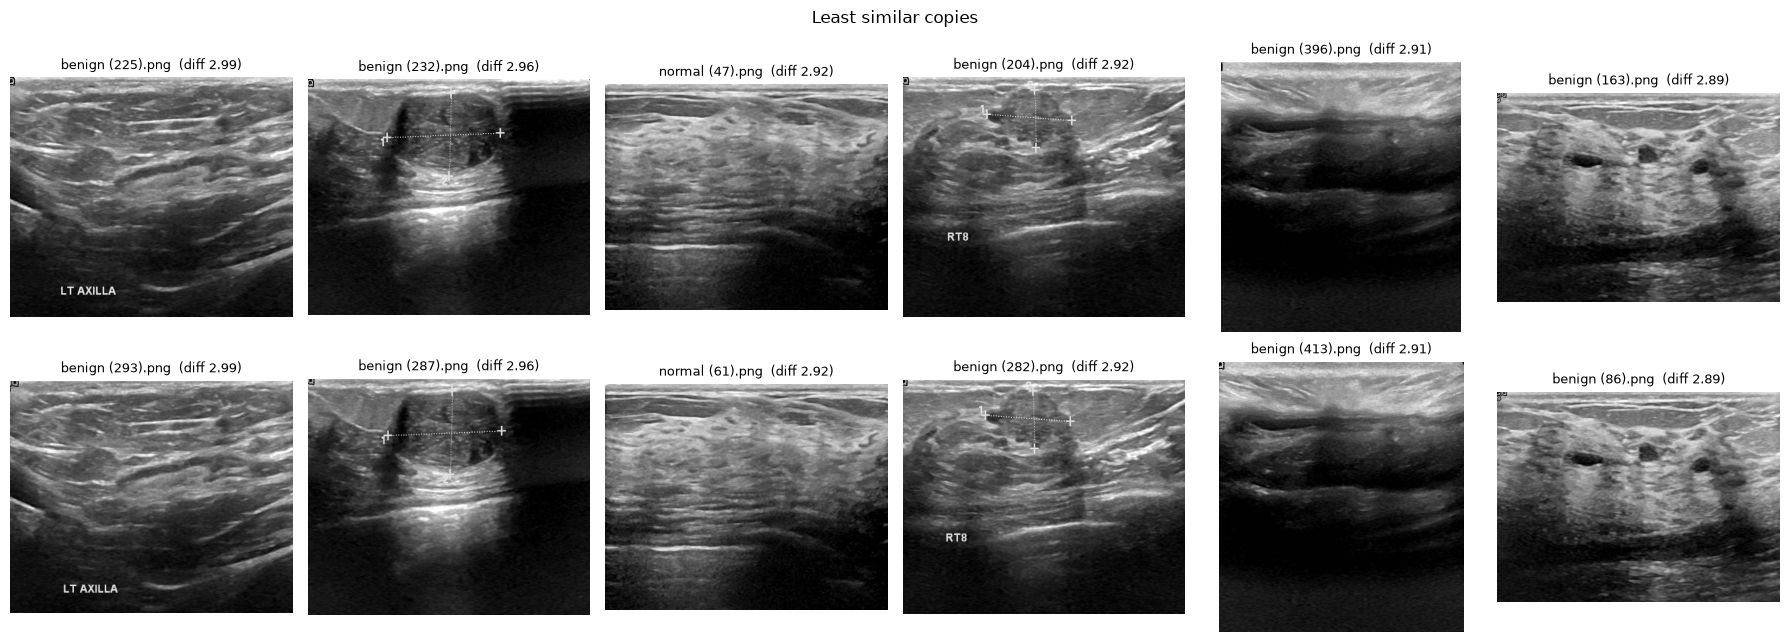

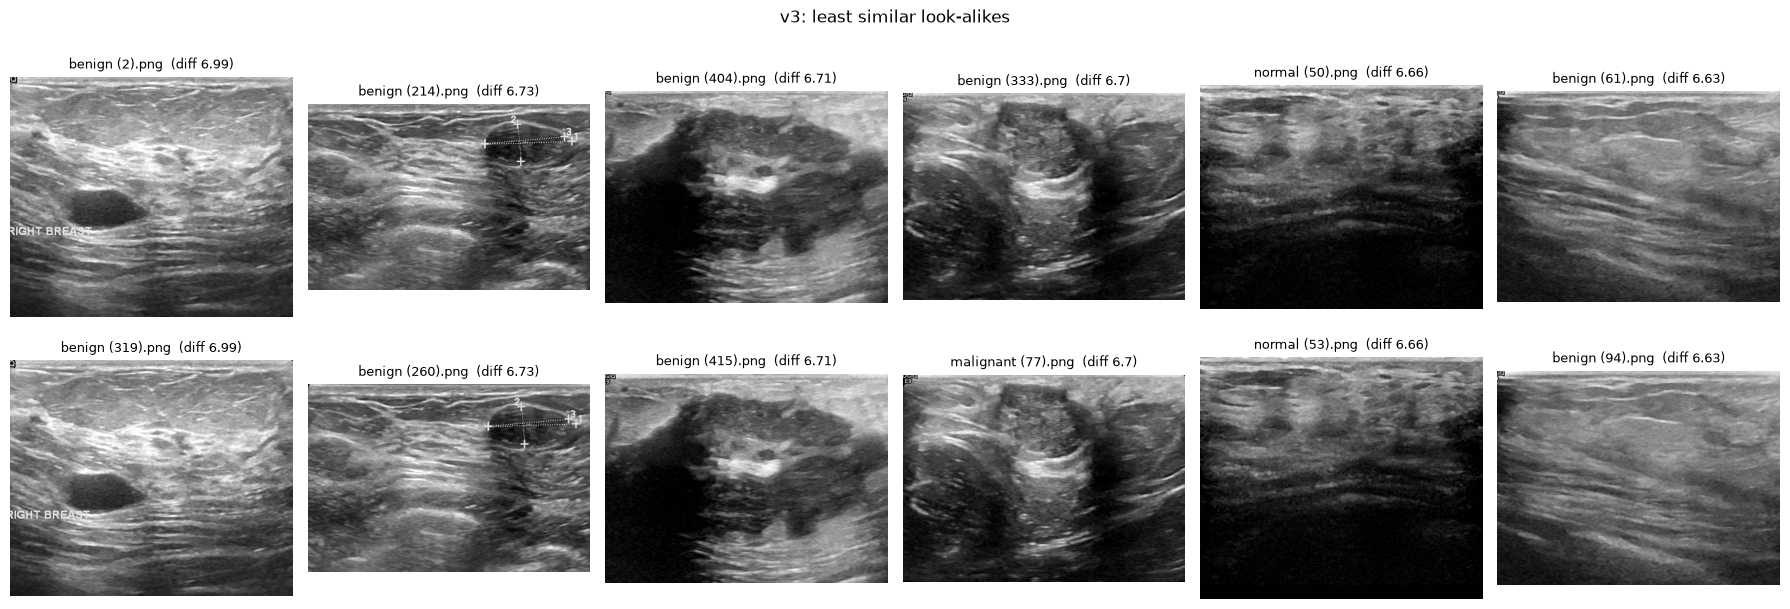

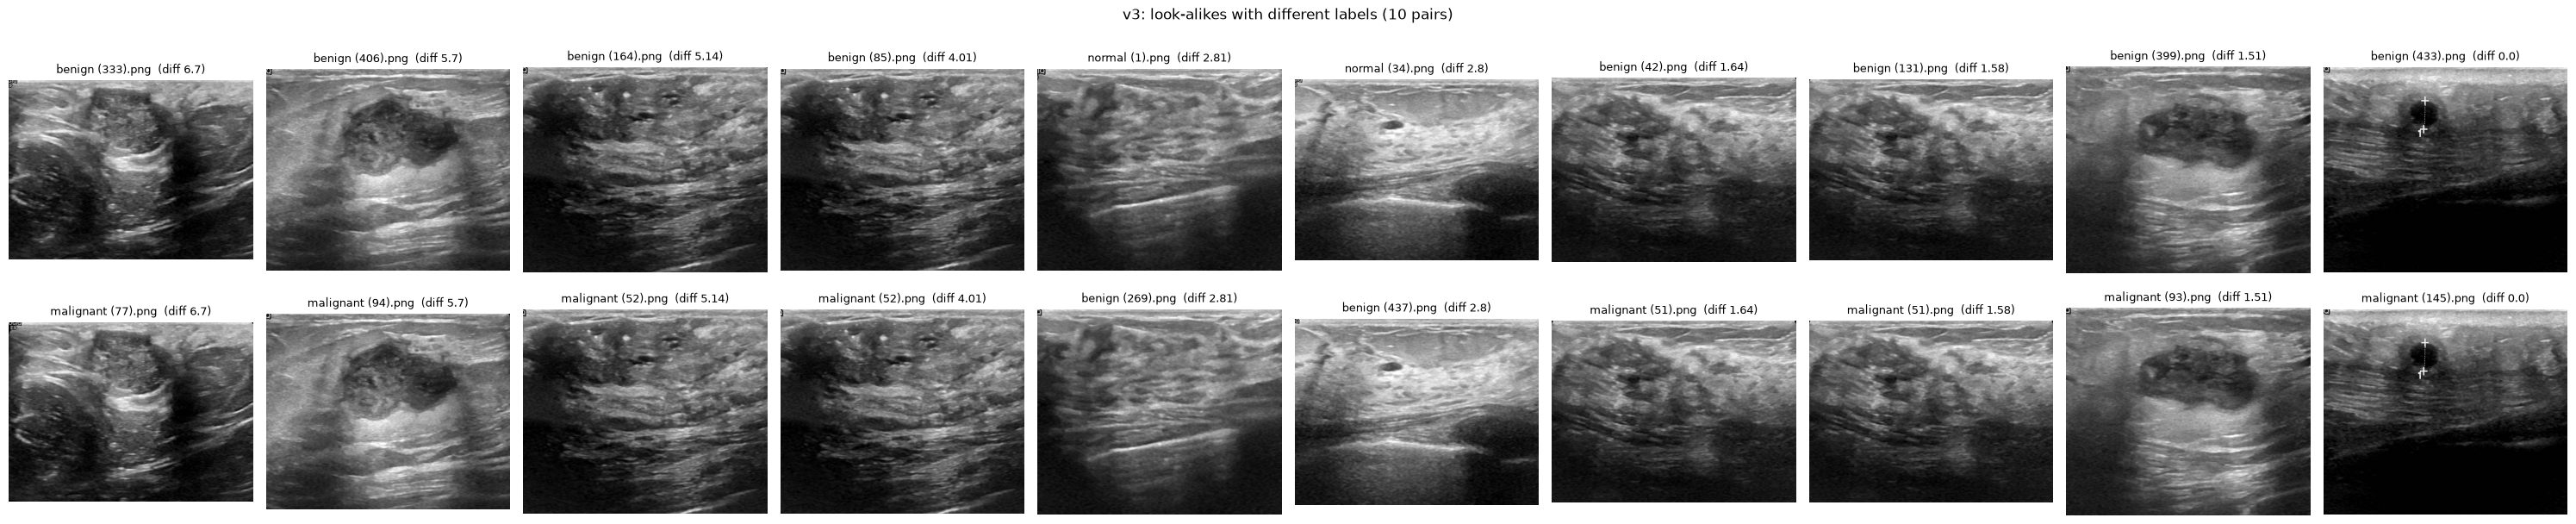

In [9]:
def show_pairs(pair_list, title, n=6):
    """Show pairs side by side: top row = first image, bottom row = its look-alike."""
    pair_list = pair_list[:n]
    if not pair_list:
        print(f'{title}: none')
        return
    fig, axes = plt.subplots(2, len(pair_list), figsize=(3 * len(pair_list), 6.5), squeeze=False)
    for col, (i, j, diff) in enumerate(pair_list):
        for row, k in enumerate([i, j]):
            path = df.loc[k, 'image_path']
            axes[row, col].imshow(load_gray(path), cmap='gray')
            axes[row, col].set_title(f'{Path(path).name}  (diff {diff})', fontsize=9)
            axes[row, col].axis('off')
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


least_similar_first = lambda pair_list: sorted(pair_list, key=lambda p: p[2], reverse=True)
cross_class = [p for p in pairs if df.loc[p[0], 'label'] != df.loc[p[1], 'label']]

show_pairs(least_similar_first(copy_pairs), 'Least similar copies')
show_pairs(least_similar_first(pairs), 'v3: least similar look-alikes')
show_pairs(least_similar_first(cross_class), f'v3: look-alikes with different labels ({len(cross_class)} pairs)', n=10)

## 5. Remove duplicates

- **Conflicting labels:** a look-alike group contains more than one class (v3: checked on look-alike groups, not just copies), so every image in the group is removed.
- **Copies with the same label:** the first copy is kept and the rest are removed.
- **Look-alikes with the same label** (not copies) are kept. They are different views, so they're useful for training, but they stay together in one split and fold (section 7).

Removed images are saved to `removed_images.csv` with the reason, so they can be reviewed later.

In [10]:
labels_per_group = df.groupby('lookalike_group')['label'].transform('nunique')   # v3: classes per look-alike group

conflicting = df[labels_per_group > 1]                                           # same scan, different labels
extra_copies = df[(labels_per_group == 1) & df.duplicated('duplicate_group')]    # 2nd, 3rd ... copy

print(f'Conflicting labels: {len(conflicting)} images')
print(f'Extra copies:       {len(extra_copies)} images')
conflicting.sort_values('lookalike_group')[['image_path', 'label', 'lookalike_group']]

Conflicting labels: 18 images
Extra copies:       75 images


,image_path,label,lookalike_group
0,normal/normal (1).png,normal,0
321,benign/benign (269).png,benign,0
61,normal/normal (34).png,normal,61
508,benign/benign (437).png,benign,61
727,malignant/malignant (51).png,malignant,169
489,benign/benign (42).png,benign,169
169,benign/benign (131).png,benign,169
205,benign/benign (164).png,benign,205
554,benign/benign (85).png,benign,205
728,malignant/malignant (52).png,malignant,205


In [11]:
removed = pd.concat([
    conflicting.assign(reason='conflicting labels'),
    extra_copies.assign(reason='duplicate copy'),
])
removed.to_csv(DATA_DIR / 'removed_images.csv', index=False)

df = df.drop(removed.index).reset_index(drop=True)
print(f'{len(removed)} images removed, {len(df)} images left')
df['label'].value_counts()

93 images removed, 687 images left


label
benign       375
malignant    200
normal       112
Name: count, dtype: int64

## 6. Flag images with markers

Some scans have measurement calipers (`+`), dotted lines or text burned in. A model could learn "markers mean tumour" instead of looking at the tissue, so we flag these images to test on clean images later.

Markers are spotted two ways:
- **Thin bright strokes:** a *white top-hat* filter keeps small bright details (lines, text) and removes large bright areas (normal tissue).
- **Coloured pixels:** ultrasound is grey, so any clearly coloured pixel is an annotation.

This is a simple rule, not a perfect detector. Check the examples below.

In [12]:
def marker_pixels(path):
    """Count pixels that look like burned-in markers: thin bright strokes or coloured marks."""
    rgb = np.array(Image.open(DATA_DIR / path).convert('RGB')).astype(int)
    gray = rgb.mean(axis=2)

    thin_bright = (gray >= 240) & (white_tophat(gray, disk(3)) > 60)   # small, very bright details
    coloured = (rgb.max(axis=2) - rgb.min(axis=2)) > 30               # red/green/blue channels differ
    return int(thin_bright.sum() + coloured.sum())


df['marker_pixels'] = df['image_path'].apply(marker_pixels)
df['has_markers'] = df['marker_pixels'] > MARKER_PIXEL_THRESHOLD

pd.crosstab(df['label'], df['has_markers'])

has_markers,False,True
label,,
benign,142,233
malignant,78,122
normal,63,49


If markers are much more common in benign/malignant images than in normal ones, a model could cheat by spotting them. That's why we flag them.

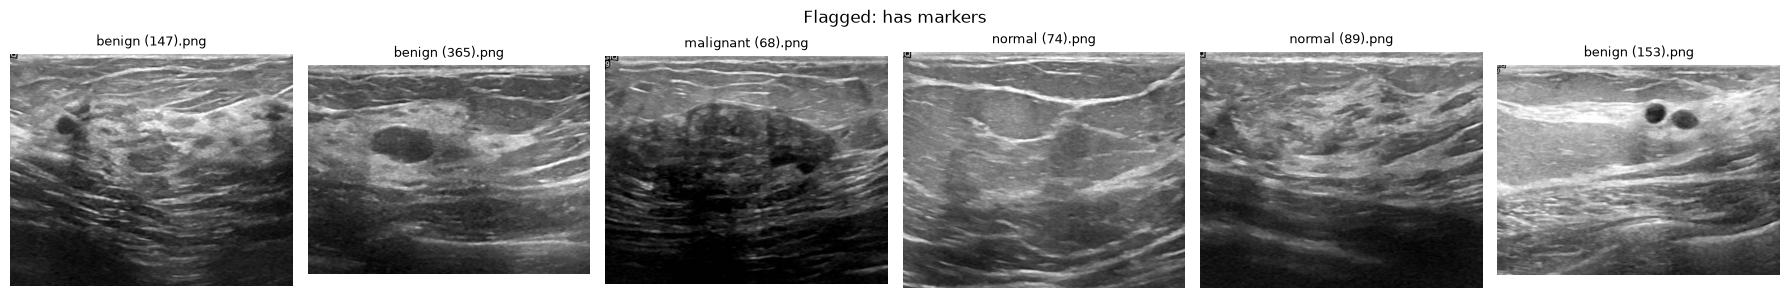

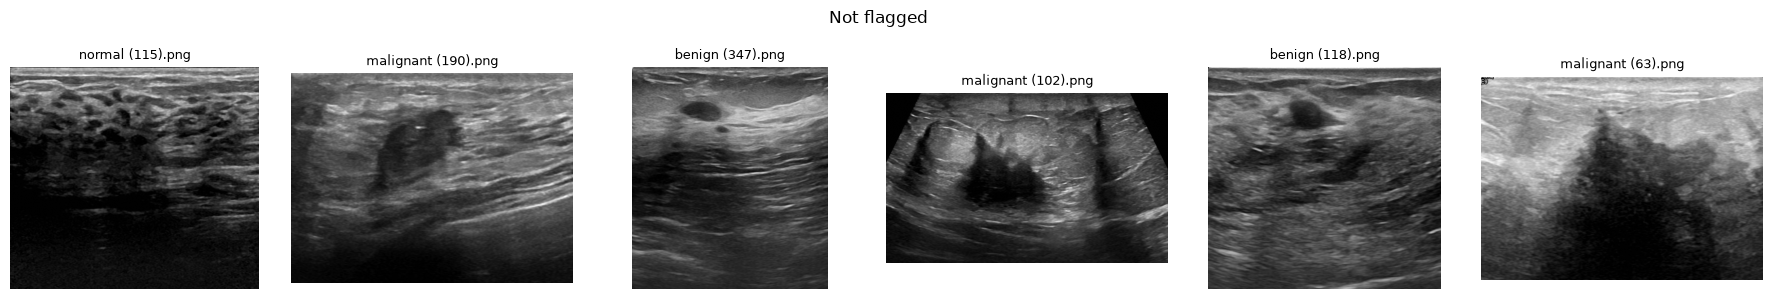

In [13]:
def show_images(paths, title):
    """Show a row of images with a title."""
    fig, axes = plt.subplots(1, len(paths), figsize=(3 * len(paths), 3), squeeze=False)
    for ax, path in zip(axes[0], paths):
        ax.imshow(load_gray(path), cmap='gray')
        ax.set_title(Path(path).name, fontsize=9)
        ax.axis('off')
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


flagged = df[df['has_markers']]
not_flagged = df[~df['has_markers']]
show_images(flagged.sample(min(6, len(flagged)), random_state=RANDOM_STATE)['image_path'], 'Flagged: has markers')
show_images(not_flagged.sample(min(6, len(not_flagged)), random_state=RANDOM_STATE)['image_path'], 'Not flagged')

## 7. Train / validation / test split

**v3:** the split now keeps look-alike images together, so the same lesion can never be in both training and testing.

1. **Test set (frozen):** the v1 test images that are still here after cleaning. Keeping the same test images means v3 can be compared directly with v1 and v2. If the v1 manifest isn't found, a new test set of about 15% is made instead, keeping look-alike groups together.
2. **Remove train/val look-alikes of test images:** if an image outside the test set is in the same look-alike group as a test image, it's removed.
3. **5 cross-validation folds** for the remaining images, stratified by class and keeping each look-alike group in one fold. **Fold 0 is the validation set** (`split = 'val'`) and folds 1–4 are training, so notebooks 01–05 work unchanged. v3's cross-validation will use all 5 folds.

In [14]:
# 1. Test set: the v1 test images that are still here (frozen), or a new grouped test set if v1 isn't available
if FROZEN_TEST.exists():
    v1_test = set(pd.read_csv(FROZEN_TEST).query("split == 'test'")['image_path'])
    is_test = df['image_path'].isin(v1_test).values
    print(f'Frozen test set: {is_test.sum()} of the {len(v1_test)} v1 test images are still here')
else:
    splitter = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=RANDOM_STATE)    # 1 of 7 parts = ~15%
    _, test_rows = next(splitter.split(df, df['label'], groups=df['lookalike_group']))
    is_test = df.index.isin(test_rows)
    print(f'No v1 manifest found: new test set of {is_test.sum()} images')
df['split'] = np.where(is_test, 'test', 'train')

# 2. Remove train/val images that are look-alikes of a test image
test_groups = set(df.loc[df['split'] == 'test', 'lookalike_group'])
leaks = df[(df['split'] != 'test') & df['lookalike_group'].isin(test_groups)]
print(f'Removed {len(leaks)} train/val images that look like a test image')

removed = pd.concat([removed, leaks.assign(reason='look-alike of a test image')])
removed.to_csv(DATA_DIR / 'removed_images.csv', index=False)
df = df.drop(leaks.index).reset_index(drop=True)

# 3. Cross-validation folds for the rest, keeping each look-alike group in one fold
df['fold'] = -1                                                   # -1 = test set
rest = df[df['split'] != 'test']
folds = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
for fold, (_, rows) in enumerate(folds.split(rest, rest['label'], groups=rest['lookalike_group'])):
    df.loc[rest.index[rows], 'fold'] = fold
df.loc[df['fold'] == 0, 'split'] = 'val'                         # fold 0 = validation for notebooks 01-05

pd.crosstab(df['label'], df['split'], margins=True)

Frozen test set: 102 of the 104 v1 test images are still here
Removed 18 train/val images that look like a test image


split,test,train,val,All
label,,,,
benign,57,246,61,364
malignant,28,136,34,198
normal,17,72,18,107
All,102,454,113,669


In [15]:
# v3: checks - no look-alike group may cross splits or folds, and folds should be balanced
groups_across_splits = (df.groupby('lookalike_group')['split'].nunique() > 1).sum()
groups_across_folds = (df[df['fold'] >= 0].groupby('lookalike_group')['fold'].nunique() > 1).sum()
print(f'Look-alike groups split across train / val / test: {groups_across_splits}  (should be 0)')
print(f'Look-alike groups split across folds:              {groups_across_folds}  (should be 0)')

# v3: how the data changed compared with v1
if FROZEN_TEST.exists():
    v1 = pd.read_csv(FROZEN_TEST)
    v1_test_gone = v1[(v1['split'] == 'test') & ~v1['image_path'].isin(df['image_path'])]
    print(f'\nImages: v1 {len(v1)} -> v3 {len(df)}')
    print(f'v1 test images no longer in the test set: {len(v1_test_gone)}', list(v1_test_gone['image_path']))
    print('\nRemoved images by reason:')
    print(removed['reason'].value_counts().to_string())

pd.crosstab(df[df['fold'] >= 0]['label'], df[df['fold'] >= 0]['fold'], margins=True)     # images per fold and class

Look-alike groups split across train / val / test: 0  (should be 0)
Look-alike groups split across folds:              0  (should be 0)

Images: v1 693 -> v3 669
v1 test images no longer in the test set: 2 ['malignant/malignant (52).png', 'malignant/malignant (94).png']

Removed images by reason:
reason
duplicate copy                75
conflicting labels            18
look-alike of a test image    18


fold,0,1,2,3,4,All
label,,,,,,
benign,61,61,61,62,62,307
malignant,34,34,34,34,34,170
normal,18,18,18,18,18,90
All,113,113,113,114,114,567


## 8. Save the manifest

Every later notebook reads this file, so they all use the same images and the same split.

In [16]:
columns = ['image_path', 'mask_paths', 'label', 'width', 'height', 'n_lesions', 'has_markers',
           'duplicate_group', 'lookalike_group', 'split', 'fold']       # v3: + lookalike_group, fold

df[columns].to_csv(DATA_DIR / 'manifest.csv', index=False)
print(f'Saved {len(df)} images to data/manifest.csv')
df[columns].head()

Saved 669 images to data/manifest.csv


,image_path,mask_paths,label,width,height,n_lesions,has_markers,duplicate_group,lookalike_group,split,fold
0,normal/normal (10).png,normal/normal (10)_mask.png,normal,501,485,0,False,1,1,train,2
1,normal/normal (100).png,normal/normal (100)_mask.png,normal,690,574,0,False,2,2,train,1
2,normal/normal (101).png,normal/normal (101)_mask.png,normal,678,572,0,False,3,3,val,0
3,normal/normal (102).png,normal/normal (102)_mask.png,normal,770,576,0,False,4,4,train,4
4,normal/normal (103).png,normal/normal (103)_mask.png,normal,772,574,0,False,5,5,test,-1
